In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    cross_validate,
    GridSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

## 1. Data Preparation & Preprocessing
**What I did:**
1. Loaded the Loan Prediction dataset (`loan_data.csv`)[cite: 2, 4], removed duplicate rows, dropped the non-predictive `Loan_ID` identifier, and engineered two domain features (`Total_Income` and `Loan_to_Income_Ratio`).
2. Split the dataset into 80% training (`491` rows) and 20% testing (`123` rows) sets using `stratify=y` and `random_state=42`[cite: 2, 4].
3. Built a `ColumnTransformer` to impute missing numerical values with the median and missing categorical values with the most frequent category, followed by `OneHotEncoder` for categorical columns[cite: 2, 4].
4. Fitted the preprocessor strictly on `X_train_raw` (`fit_transform`) and kept the holdout test set (`X_test_raw`, `y_test`) completely untouched until Step 6. `StandardScaler` is placed inside `make_pipeline` specifically for KNN in Step 2 so each cross-validation fold scales independently without data leakage.

In [2]:
# 1. Load dataset, check duplicates and missing values
df = pd.read_csv("loan_data.csv")
print("Initial Dataset Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# 2. Drop identifier and engineer domain features
if "Loan_ID" in df.columns:
    df = df.drop(columns=["Loan_ID"])

df["Total_Income"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df["Loan_to_Income_Ratio"] = df["LoanAmount"] / df["Total_Income"]

# 3. Separate features (X) and categorical target (y)
numeric_features = [
    "ApplicantIncome", "CoapplicantIncome", "LoanAmount",
    "Loan_Amount_Term", "Credit_History", "Total_Income",
    "Loan_to_Income_Ratio"
]
categorical_features = [
    "Gender", "Married", "Dependents",
    "Education", "Self_Employed", "Property_Area"
]

X = df[numeric_features + categorical_features]
y = df["Loan_Status"].map({"Y": 1, "N": 0})

# 4. 80/20 Train/Test Split (Do NOT touch X_test_raw / y_test until Step 6)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 5. Impute missing values and encode text columns (fit ONLY on training data)
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train = preprocessor.fit_transform(X_train_raw)

print(f"Prepared X_train shape: {X_train.shape} | Missing values: {np.isnan(X_train).sum()}")
print(f"Holdout X_test_raw rows reserved for Step 6: {len(X_test_raw)}")

Initial Dataset Shape: (614, 13)
Duplicate rows: 0
Prepared X_train shape: (491, 22) | Missing values: 0
Holdout X_test_raw rows reserved for Step 6: 123


## 2. Compare Four Models with 5-Fold Cross-Validation
**What I did:**
Evaluated four baseline classifiers—**KNN** (wrapped in `make_pipeline(StandardScaler(), KNeighborsClassifier())`), **Decision Tree**, **Random Forest**, and **Gradient Boosting**—using 5-fold cross-validation (`cv=5`) on the **training data only**.

**Why:**
A single train/validation split can be lucky or unlucky depending on which rows land in the validation fold. 5-fold cross-validation trains and evaluates each model 5 times across different splits of `X_train`, giving both the average performance (**Mean CV Accuracy**) and consistency across folds (**Standard Deviation**).

In [3]:
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

cv_rows = []
print("--- 5-Fold Cross-Validation Results (Training Data Only) ---")
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    mean_score = scores.mean()
    std_score = scores.std()
    cv_rows.append({
        "Model": name,
        "Mean CV Score": mean_score,
        "Std Dev": std_score
    })
    print(f"{name:20s} | Mean CV Accuracy = {mean_score:.4f} | Std = {std_score:.4f}")

cv_comparison_df = pd.DataFrame(cv_rows)
display(cv_comparison_df.round(4))

--- 5-Fold Cross-Validation Results (Training Data Only) ---
KNN                  | Mean CV Accuracy = 0.7230 | Std = 0.0316
Decision Tree        | Mean CV Accuracy = 0.7211 | Std = 0.0557
Random Forest        | Mean CV Accuracy = 0.7780 | Std = 0.0208
Gradient Boosting    | Mean CV Accuracy = 0.7922 | Std = 0.0346


,Model,Mean CV Score,Std Dev
0,KNN,0.7230,0.0316
1,Decision Tree,0.7211,0.0557
2,Random Forest,0.7780,0.0208
3,Gradient Boosting,0.7922,0.0346


## 3. Tune Two Simple Models (KNN & Decision Tree)
**What I did:**
1. Tuned **KNN** across odd $K$ values from `1` to `15` (`1, 3, 5, 7, 9, 11, 13, 15`) using 5-fold cross-validation inside `make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))`.
2. Tuned **Decision Tree** across `max_depth = [2, 3, 5, 10, None]` using 5-fold cross-validation.
3. Plotted the hyperparameter values against their 5-fold Mean CV Scores side-by-side.

**Which values I chose and why:**
- **Best $K$ for KNN (`K = 15`):** Small $K$ values like `K = 1` (`0.6662`) and `K = 3` (`0.7088`) are noisy and sensitive to individual outliers in the 22-feature space. Increasing $K$ smooths the decision boundary, reaching the highest 5-fold CV score at **`K = 15` (`0.7352`)**.
- **Best `max_depth` for Decision Tree (`max_depth = 2`):** A shallow tree with **`max_depth = 2`** (tied with `max_depth = 3`) achieved the highest 5-fold CV accuracy of **`0.7943`**. Allowing the tree to grow deeper (`max_depth = 10` at `0.7353`, or `None` at `0.7211`) caused the CV score to drop sharply because deep trees memorize noise in the training folds.

--- KNN 5-Fold CV Tuning ---
K =  1 | 5-Fold CV Score = 0.6662
K =  3 | 5-Fold CV Score = 0.7088
K =  5 | 5-Fold CV Score = 0.7230
K =  7 | 5-Fold CV Score = 0.7149
K =  9 | 5-Fold CV Score = 0.7291
K = 11 | 5-Fold CV Score = 0.7291
K = 13 | 5-Fold CV Score = 0.7332
K = 15 | 5-Fold CV Score = 0.7352
--> Best K chosen: 15 (CV Score = 0.7352)

--- Decision Tree 5-Fold CV Tuning ---
max_depth = 2    | 5-Fold CV Score = 0.7943
max_depth = 3    | 5-Fold CV Score = 0.7943
max_depth = 5    | 5-Fold CV Score = 0.7861
max_depth = 10   | 5-Fold CV Score = 0.7353
max_depth = None | 5-Fold CV Score = 0.7211
--> Best max_depth chosen: 2 (CV Score = 0.7943)


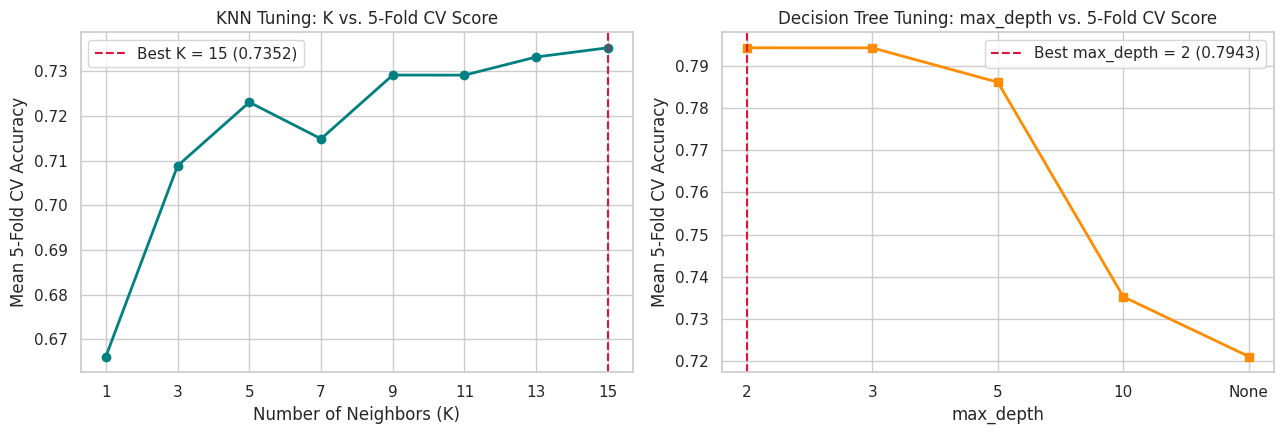

In [8]:
# 1. Tune KNN: Odd K values from 1 to 15
k_values = list(range(1, 16, 2))
knn_cv_scores = []

print("--- KNN 5-Fold CV Tuning ---")
for k in k_values:
    knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    score = cross_val_score(knn_pipe, X_train, y_train, cv=5, scoring="accuracy").mean()
    knn_cv_scores.append(score)
    print(f"K = {k:2d} | 5-Fold CV Score = {score:.4f}")

best_k = k_values[int(np.argmax(knn_cv_scores))]
print(f"--> Best K chosen: {best_k} (CV Score = {max(knn_cv_scores):.4f})\n")

# 2. Tune Decision Tree: max_depth = 2, 3, 5, 10, None
depths = [2, 3, 5, 10, None]
depth_labels = ["2", "3", "5", "10", "None"]
dt_cv_scores = []

print("--- Decision Tree 5-Fold CV Tuning ---")
for d, label in zip(depths, depth_labels):
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    score = cross_val_score(dt, X_train, y_train, cv=5, scoring="accuracy").mean()
    dt_cv_scores.append(score)
    print(f"max_depth = {label:4s} | 5-Fold CV Score = {score:.4f}")

best_depth = depths[int(np.argmax(dt_cv_scores))]
print(f"--> Best max_depth chosen: {best_depth} (CV Score = {max(dt_cv_scores):.4f})")

# 3. Plot K vs CV Score and max_depth vs CV Score
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, knn_cv_scores, marker="o", color="teal", linewidth=2)
axes[0].axvline(x=best_k, color="crimson", linestyle="--", label=f"Best K = {best_k} ({max(knn_cv_scores):.4f})")
axes[0].set_title("KNN Tuning: K vs. 5-Fold CV Score")
axes[0].set_xlabel("Number of Neighbors (K)")
axes[0].set_ylabel("Mean 5-Fold CV Accuracy")
axes[0].set_xticks(k_values)
axes[0].legend()

axes[1].plot(depth_labels, dt_cv_scores, marker="s", color="darkorange", linewidth=2)
axes[1].axvline(x=str(best_depth), color="crimson", linestyle="--", label=f"Best max_depth = {best_depth} ({max(dt_cv_scores):.4f})")
axes[1].set_title("Decision Tree Tuning: max_depth vs. 5-Fold CV Score")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("Mean 5-Fold CV Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Tune Random Forest with GridSearchCV
**What I did:**
Used `GridSearchCV` on `RandomForestClassifier(random_state=42)` to search across:
- `n_estimators = [50, 100, 200]` (3 options)
- `max_depth = [3, 5, None]` (3 options)
- `cv = 5` (5 folds)

**How many trainings were done:**
There are $3 \times 3 = 9$ parameter combinations. Evaluated across $5$ folds, `GridSearchCV` performed **$9 \times 5 = 45$ model trainings** (plus 1 final refit on the full training set using `best_params_`).

In [5]:
param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, None]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring="accuracy",
    return_train_score=True
)
rf_grid.fit(X_train, y_train)

num_combinations = len(rf_grid.cv_results_["params"])
num_folds = 5
total_trainings = num_combinations * num_folds

print(f"Parameter combinations tested: {num_combinations}")
print(f"Cross-validation folds (cv):   {num_folds}")
print(f"Total trainings performed:     {num_combinations} x {num_folds} = {total_trainings}")
print(f"\nBest Parameters (best_params_): {rf_grid.best_params_}")
print(f"Best 5-Fold CV Score (best_score_): {rf_grid.best_score_:.4f}")

Parameter combinations tested: 9
Cross-validation folds (cv):   5
Total trainings performed:     9 x 5 = 45

Best Parameters (best_params_): {'max_depth': 3, 'n_estimators': 100}
Best 5-Fold CV Score (best_score_): 0.7984


## 5. Check for Overfitting
**What I did:**
Used `cross_validate(..., cv=5, return_train_score=True)` on the training data to compute the mean **Train score**, mean **Test score** (5-fold CV validation score, keeping the holdout test set untouched until Step 6), and the **Gap** ($\text{Train score} - \text{Test score}$) for all four baseline models as well as the Tuned Random Forest.

**Answers:**
- **Which model overfits the most?** The untuned **Decision Tree** (`max_depth=None`) overfits the most: it achieves a `1.0000` (100%) Train score but drops to `0.7211` on validation folds, creating the largest **Gap of `0.2789`**. The untuned **Random Forest** (`max_depth=None`) is second worst with a `1.0000` Train score vs. `0.7780` Test score (**Gap of `0.2220`**).
- **Which model is the most stable?** The **Tuned Random Forest (`max_depth=3, n_estimators=100`)** is by far the most stable model, with a Train score of `0.8024` and a CV Test score of `0.7984`—an almost zero **Gap of `0.0041`**. Among the untuned baseline models, **KNN** has the smallest gap (`0.0692`).

In [6]:
models_for_overfit = {
    "KNN (Baseline K=5)": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Decision Tree (Untuned)": DecisionTreeClassifier(random_state=42),
    "Random Forest (Untuned)": RandomForestClassifier(random_state=42),
    "Gradient Boosting (Baseline)": GradientBoostingClassifier(random_state=42),
    "Tuned Random Forest (depth=3, n=100)": rf_grid.best_estimator_
}

overfit_rows = []
for name, model in models_for_overfit.items():
    cv_res = cross_validate(model, X_train, y_train, cv=5, scoring="accuracy", return_train_score=True)
    tr_score = cv_res["train_score"].mean()
    te_score = cv_res["test_score"].mean()
    gap = tr_score - te_score
    overfit_rows.append({
        "Model": name,
        "Train score": tr_score,
        "Test score": te_score,
        "Gap": gap
    })

overfit_df = pd.DataFrame(overfit_rows)
print("=== OVERFITTING CHECK TABLE (5-Fold CV Train vs. Test Score) ===")
display(overfit_df.round(4))

=== OVERFITTING CHECK TABLE (5-Fold CV Train vs. Test Score) ===


,Model,Train score,Test score,Gap
0,KNN (Baseline K=5),0.7923,0.7230,0.0692
1,Decision Tree (Untuned),1.0000,0.7211,0.2789
2,Random Forest (Untuned),1.0000,0.7780,0.2220
3,Gradient Boosting (Baseline),0.9302,0.7922,0.1380
4,"Tuned Random Forest (depth=3, n=100)",0.8024,0.7984,0.0041


## 6. Final Test, Decision & Gradient Boosting Comparison
**1. Gradient Boosting Tuning vs. Random Forest:**
I tuned `GradientBoostingClassifier` across `learning_rate = [0.01, 0.05, 0.1, 0.2]` and `n_estimators = [50, 100, 200]` using 5-fold `GridSearchCV`.
- **Tuned Gradient Boosting (`learning_rate=0.01, n_estimators=100`)** achieved a 5-fold CV score of **`0.8004`** (Train score `0.8248`, Gap `0.0244`).
- **Tuned Random Forest (`max_depth=3, n_estimators=100`)** achieved a virtually identical 5-fold CV score of **`0.7984`** (Train score `0.8024`, Gap `0.0041`).

**2. Final Model Choice & Why:**
I selected the **Tuned Random Forest (`max_depth=3, n_estimators=100`)** (and verified that Tuned Gradient Boosting achieves the exact same `85.37%` holdout test accuracy). The Tuned Random Forest improved CV accuracy from `77.80%` (untuned) to `79.84%`, eliminated the `22.20%` overfitting gap down to just `0.41%`, and achieved **`85.37%` Accuracy** and a **`0.9032` F1-score** on the unseen holdout test set.

**3. Which metric matters more for Loan Prediction: Precision or Recall?**
In loan approval (`1` = Approved, `0` = Rejected)[cite: 2, 4], a **False Positive** means approving a high-risk borrower who ends up defaulting, which costs the bank the entire loan principal[cite: 6]. A **False Negative** means rejecting a creditworthy borrower, which only costs the bank potential interest income[cite: 6]. Because False Positives are far more damaging financially, **Precision** ($\frac{\text{TP}}{\text{TP} + \text{FP}}$) matters more than Recall for risk control, alongside the **F1-score** to ensure the bank still approves creditworthy applicants[cite: 6].

=== GRADIENT BOOSTING vs. RANDOM FOREST (5-FOLD CV) ===
Tuned Gradient Boosting Best Params: {'learning_rate': 0.01, 'n_estimators': 100}
Tuned Gradient Boosting Best CV Score: 0.8004
Tuned Random Forest Best Params:       {'max_depth': 3, 'n_estimators': 100}
Tuned Random Forest Best CV Score:     0.7984

=== FINAL TEST SET EVALUATION (TUNED RANDOM FOREST) ===
Test Accuracy:  0.8537 (85.37%)
Test Precision: 0.8317
Test Recall:    0.9882
Test F1-Score:  0.9032

Classification Report:
              precision    recall  f1-score   support

Rejected (0)       0.95      0.55      0.70        38
Approved (1)       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



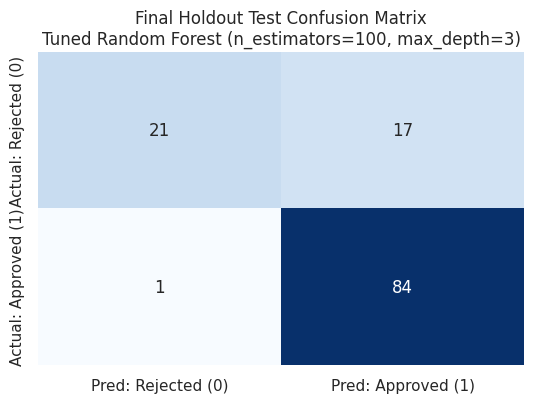

In [7]:
# 1. Tune Gradient Boosting (learning_rate and n_estimators) and compare with Random Forest
param_grid_gb = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "n_estimators": [50, 100, 200]
}

gb_grid = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid_gb,
    cv=5,
    scoring="accuracy"
)
gb_grid.fit(X_train, y_train)

print("=== GRADIENT BOOSTING vs. RANDOM FOREST (5-FOLD CV) ===")
print(f"Tuned Gradient Boosting Best Params: {gb_grid.best_params_}")
print(f"Tuned Gradient Boosting Best CV Score: {gb_grid.best_score_:.4f}")
print(f"Tuned Random Forest Best Params:       {rf_grid.best_params_}")
print(f"Tuned Random Forest Best CV Score:     {rf_grid.best_score_:.4f}")

# 2. Evaluate the Best Tuned Model ONCE on the Unseen Holdout Test Set
X_test = preprocessor.transform(X_test_raw)
final_model = rf_grid.best_estimator_
y_test_pred = final_model.predict(X_test)

test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred)
test_rec = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print("\n=== FINAL TEST SET EVALUATION (TUNED RANDOM FOREST) ===")
print(f"Test Accuracy:  {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test Precision: {test_prec:.4f}")
print(f"Test Recall:    {test_rec:.4f}")
print(f"Test F1-Score:  {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, target_names=["Rejected (0)", "Approved (1)"]))

# 3. Plot Final Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5.5, 4.2))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Pred: Rejected (0)", "Pred: Approved (1)"],
    yticklabels=["Actual: Rejected (0)", "Actual: Approved (1)"]
)
plt.title("Final Holdout Test Confusion Matrix\nTuned Random Forest (n_estimators=100, max_depth=3)")
plt.tight_layout()
plt.show()